# 01 · Auditoria dos dados
Base bruta `Dados-IDA.xls` (superconjunto da base da monografia). Detalhes em `docs/data_quality_report.md`.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for sub in ("data", "targets", "features", "validation"):
    sys.path.insert(0, str(ROOT / "src" / sub))
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
TAB = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from clean_base import build_clean_base, load_raw
clean = build_clean_base(load_raw())
print(clean.shape, clean['date'].min().date(), clean['date'].max().date())
clean.head()

(4240, 26) 2009-01-05 2025-11-19


,date,ida_index,ida_ret,duration,ipca_deb_ret,ibov_ret,cdi_ret,excess_ret,ida_index_ret,ida_trail_10,cdi_trail_10,excess_trail_10,ida_trail_20,cdi_trail_20,excess_trail_20,ida_trail_30,cdi_trail_30,excess_trail_30,ida_trail_60,cdi_trail_60,excess_trail_60,in_original_sample,has_duration,ibov_from_text,ibov_zero_no_trading,ida_ret_index_mismatch
0,2009-01-05,755.572589,0.000974,NaN,0.002719,0.0317,0.000506,0.000468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False
1,2009-01-06,755.177562,-0.000523,NaN,0.001907,0.0191,0.000506,-0.001029,-0.000523,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False
2,2009-01-07,754.855004,-0.000427,NaN,0.000642,-0.0353,0.000506,-0.000933,-0.000427,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False
3,2009-01-08,755.035562,0.000239,NaN,0.002119,0.0287,0.000506,-0.000267,0.000239,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False
4,2009-01-09,755.350404,0.000417,NaN,-0.000575,-0.0097,0.000506,-0.000089,0.000417,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False


## Valores ausentes e flags de rastreabilidade

In [2]:
display(pd.read_csv(TAB / 'missing_values.csv', index_col=0).query('n_nan > 0'))
clean[['in_original_sample','has_duration','ibov_from_text','ibov_zero_no_trading','ida_ret_index_mismatch']].sum()

,n_nan,n_nan_original_sample
duration,59,0
ida_index_ret,1,0
ida_trail_10,9,0
cdi_trail_10,9,0
excess_trail_10,9,0
ida_trail_20,19,0
cdi_trail_20,19,0
excess_trail_20,19,0
ida_trail_30,29,0
cdi_trail_30,29,0


in_original_sample        4181
has_duration              4181
ibov_from_text              18
ibov_zero_no_trading        64
ida_ret_index_mismatch       4
dtype: int64

## Reconciliação com a base da monografia
Colunas idênticas, exceto `CDI_20_dias` (janela de 19 dias na monografia) e a escala do IPCA.

In [3]:
pd.read_csv(TAB / 'reconciliation_raw_vs_monograph.csv')

,clean_col,monograph_col,max_abs_diff,n_rows_diff_gt_1e-9
0,ida_index,ida_index_m,0.000000e+00,0
1,ida_ret,ida_ret_m,0.000000e+00,0
2,duration,duration_m,0.000000e+00,0
3,ipca_deb_ret,ipca_deb_pct,3.469447e-18,0
4,ibov_ret,ibov_ret_m,0.000000e+00,0
5,cdi_ret,cdi_ret_m,0.000000e+00,0
6,ida_trail_10,ida_10,1.110223e-15,0
7,cdi_trail_10,cdi_10,1.110223e-15,0
8,excess_trail_10,excess_10,1.332268e-15,0
9,ida_trail_20,ida_20,1.554312e-15,0


## Retorno do IDA × variação do nível do índice (4 dias divergem)

In [4]:
pd.read_csv(TAB / 'ida_return_vs_index_mismatch.csv')

,date,ida_index,ida_ret,ida_index_ret,diff
0,2020-11-30,2449.690497,-0.000048,0.002116,-0.002164
1,2022-05-30,2786.448096,0.000518,0.004685,-0.004167
2,2025-04-01,4009.021968,0.000402,-0.005373,0.005775
3,2025-09-16,4298.169741,0.000760,-0.002048,0.002808


## IDA e CDI acumulados (base 100)

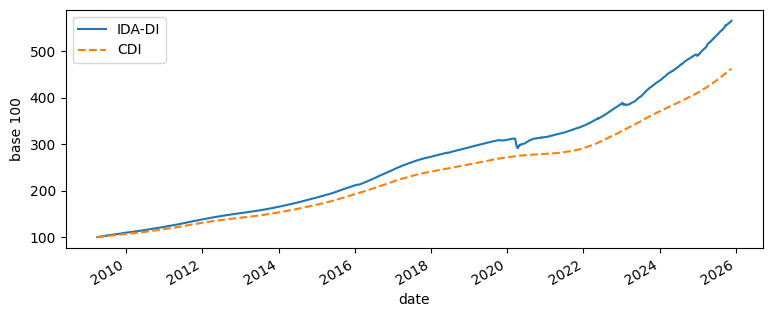

In [5]:
s = clean[clean['in_original_sample']].set_index('date')
fig, ax = plt.subplots(figsize=(9, 3.5))
(100*(1+s['ida_ret']).cumprod()).plot(ax=ax, label='IDA-DI')
(100*(1+s['cdi_ret']).cumprod()).plot(ax=ax, label='CDI', ls='--')
ax.legend(); ax.set_ylabel('base 100'); plt.show()